## Segundo paso: análisar los dataset .csv de (AAEC, ArGPT, MTC, AASS)

In [141]:
import pandas as pd
from tabulate import tabulate
import networkx as nx
import matplotlib.pyplot as plt
from networkx.drawing.nx_pydot import graphviz_layout
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np
import seaborn as sns
from collections import defaultdict

In [142]:
result_path = "./../results/minimal_v6/"

In [143]:
def di_graph(text_id, G):

    pos = graphviz_layout(G, prog="dot")

    plt.figure(figsize=(14, 10))
    
    # Separar aristas por tipo de relación
    edges_support = [(u, v) for u, v, d in G.edges(data=True)
                    if d.get("label") == "support"]

    edges_attack = [(u, v) for u, v, d in G.edges(data=True)
                    if d.get("label") == "attack"]


    # Separar nodos por tipo y asignar color
    nodes_premise     = [n for n, d in G.nodes(data=True) if d.get("component") == "Premise"]
    nodes_majorclaim  = [n for n, d in G.nodes(data=True) if d.get("component") == "MajorClaim"]
    nodes_other       = [n for n in G.nodes() if n not in nodes_premise and n not in nodes_majorclaim]

    # Dibujar nodos por grupo
    nx.draw_networkx_nodes(G, pos, nodelist=nodes_premise,    node_color="lightgreen", node_size=1500)
    nx.draw_networkx_nodes(G, pos, nodelist=nodes_majorclaim, node_color="orange",     node_size=1500)
    nx.draw_networkx_nodes(G, pos, nodelist=nodes_other,      node_color="lightblue",  node_size=1500)


    # Dibujar etiquetas de nodos
    labels = {n: n.split("_")[-1] for n in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=9)

    # Dibujar aristas con flechas visibles
    nx.draw_networkx_edges(G, pos, edgelist=edges_support,
                           edge_color="blue",
                           arrows=True,
                           arrowsize=20,
                           arrowstyle="-|>",
                           connectionstyle="arc3,rad=0.1",
                           min_source_margin=15,
                           min_target_margin=15)

    nx.draw_networkx_edges(G, pos, edgelist=edges_attack,
                           edge_color="red",
                           arrows=True,
                           arrowsize=20,
                           arrowstyle="-|>",
                           connectionstyle="arc3,rad=0.1",
                           min_source_margin=15,
                           min_target_margin=15)

    # Mostrar etiquetas de aristas
    edge_labels = nx.get_edge_attributes(G, "label")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels,
                                font_size=9, rotate=False)

    # Leyenda
    legend = [
        Patch(color="lightgreen", label="Premise"),
        Patch(color="orange",     label="MajorClaim"),
        Patch(color="lightblue",  label="Other"),
    ]
    plt.legend(handles=legend, loc="upper left")
    
    plt.title(f"Grafo argumentativo: {text_id}", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

In [144]:
def summary_comp_val_bool():
    df = pd.read_pickle(result_path + "dataframe_summary.pkl")
    bool_cols = ["is_acyclic", "is_connected", "is_tree", "is_arborescence", "is_forest"]
    bool_cols = ["aciclico", "conexo", "arvore", "arborecente", "floresta"]

    def extraer_porcentaje_true(valor):
        """Extrae el % de True de un string como '639: False, 91: True'"""
        total = 0
        true_count = 0
        for parte in str(valor).split(","):
            parte = parte.strip()
            count, estado = parte.split(":")
            count = int(count.strip())
            estado = estado.strip()
            total += count
            if estado == "True":
                true_count += count
        return (true_count / total) * 100

    # Construir matriz para el heatmap
    heatmap_data = df[bool_cols].applymap(extraer_porcentaje_true)
    # Graficar
    fig, ax = plt.subplots(figsize=(10, 6))
    im = ax.imshow(heatmap_data.values, cmap="Blues", aspect="auto", vmin=0, vmax=100)
    # Etiquetas ejes
    ax.set_xticks(range(len(bool_cols)))
    ax.set_xticklabels(bool_cols, rotation=45, ha="right", fontsize=10)
    ax.set_yticks(range(len(heatmap_data)))
    ax.set_yticklabels(heatmap_data.index, fontsize=10)
    # Valores dentro de cada celda
    for i in range(len(heatmap_data)):
        for j in range(len(bool_cols)):
            val = heatmap_data.iloc[i, j]
            color = "white" if val > 60 else "black"
            ax.text(j, i, f"{val:.1f}%", ha="center", va="center", fontsize=9, color=color)

    plt.colorbar(im, ax=ax, label="% True")
    plt.title("Property of graphs per dataset")
    plt.tight_layout()
    plt.show()

In [187]:
def summary_comp_val_num(df):    
    # 1. Convertir a formato long
    num_cols = ["n_nodes", "n_edges", "n_isolates", "n_comp", "n_root"]

    df_long = df.melt(
        id_vars=["text_id", "dataset"],
        value_vars=num_cols,
        var_name="variable",
        value_name="value"
    )

    # 2. Separar en dos grupos por escala
    grupo1 = ["n_nodes", "n_edges"]
    grupo2 = ["n_isolates", "n_comp", "n_root"]

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Grupo 1
    sns.boxplot(
        data=df_long[df_long["variable"].isin(grupo1)],
        x="variable", y="value", hue="dataset",
        ax=axes[0], palette="Set2"
    )
    axes[0].set_title("n_nodes, n_edges by dataset")
    axes[0].set_xlabel("")
    axes[0].legend(title="Dataset", fontsize=8)

    # Grupo 2
    sns.boxplot(
        data=df_long[df_long["variable"].isin(grupo2)],
        x="variable", y="value", hue="dataset",
        ax=axes[1], palette="Set2"
    )
    axes[1].set_title("n_isolates, n_comp, n_root by dataset")
    axes[1].set_xlabel("")
    axes[1].legend(title="Dataset", fontsize=8)

    plt.suptitle("Distribution of structural components of the graph", fontsize=13)
    plt.tight_layout()
    plt.show()

In [146]:
def plot_estadisticas(df):
    bool_cols = ["is_acyclic", "is_connected", "is_tree", "is_arborescence", "is_forest"]
    num_cols  = ["n_nodes", "n_edges", "n_isolates", "n_comp", "n_root"]

    # Convertir a numérico
    df[num_cols] = df[num_cols].astype(int)
    # Convertir columnas booleanas a bool
    df[bool_cols] = df[bool_cols].astype(bool)

    resultado = (df[bool_cols].mean() * 100).round(2).reset_index()
    resultado.columns = ["Propiedad", "% True"]
    resultado["% True"] = resultado["% True"].astype(str)

    # Estadísticas
    print("=== Estadísticas ===")
    print(tabulate(df[num_cols].describe(), headers='keys', tablefmt='rounded_outline', showindex=True))
    print(tabulate(resultado, headers='keys', tablefmt='rounded_outline', showindex=False))

In [147]:
# Extre el nombre del dataset desde un id
def extraer_dataset(text_id):
    for dataset in DATASETS:
        if text_id.startswith(dataset):
            return dataset
    return "unknown"

# Verificar se o raiz do grafo é MajorClaim
def verificar_raices(G):
    raices = [n for n, d in G.in_degree() if d == 0]
    
    resultado = {}
    for nodo in raices:
        tipo = G.nodes[nodo].get("component", "unknown")
        is_major_claim = tipo == "MajorClaim"
        resultado[nodo] = {
            "tipo": tipo,
            "es_MajorClaim": is_major_claim
        }
    
    return resultado

# Filtra nós raiz con/sin MajorClaim
def filtrar_con_major(diccionario):
    resultado = {}
    for text_id, raices in diccionario.items():
        con_major = any(info["es_MajorClaim"] for info in raices.values())
        if con_major:
            resultado[text_id] = raices
    return resultado, "con"

def filtrar_sin_major(diccionario):
    resultado = {}
    for text_id, raices in diccionario.items():
        sin_major = not any(info["es_MajorClaim"] for info in raices.values())
        if sin_major:
            resultado[text_id] = raices
    return resultado, "sin"

# Devuelve un summary de los valores extraidos con/sin MajorClaim
def resumen_por_dataset(problemas):
    resumen = defaultdict(int)
    
    for text_id in problemas.keys():
        dataset = extraer_dataset(text_id)
        resumen[dataset] += 1
    
    return dict(resumen)

### Dataset

In [148]:
# Lista de Dataframes
datasets = {
    "CDCP":             "CDCP_Minimal_Grafo.pkl",
    "AAEC":             "AAEC_Minimal_Grafo.pkl",
    "ArGPT":            "ArGPT_Minimal_Grafo.pkl",
    "MTC":              "MTC_Minimal_Grafo.pkl",
    "AASD":             "AASD_Minimal_Grafo.pkl",
    "AbstRCT_glaucoma": "AbstRCT_glaucoma_Minimal_Grafo.pkl",
    "AbstRCT_mixed":    "AbstRCT_mixed_Minimal_Grafo.pkl",
    "AbstRCT_neoplasm": "AbstRCT_neoplasm_Minimal_Grafo.pkl",
    "ACSP":             "ACSP_Minimal_Grafo.pkl",
    "AMP":              "AMP_Minimal_Grafo.pkl",
    "USD":              "USD_Minimal_Grafo.pkl",
}
# Lista de nomes de cada dataset
DATASETS = datasets.keys()

In [149]:
# Cargar el DataFrame
dfs = []
for name, file in datasets.items():
    df = pd.read_pickle(result_path + file)
    df["dataset"] = name
    dfs.append(df)

df_all = pd.concat(dfs, ignore_index=True)
# print(df_all["dataset"].value_counts())
print(df_all.shape)
# df_all

(5017, 15)


In [230]:
# Filtrar dataset
# FILTER = ["ArGPT", "USD", "ACSP", "AMP"]
FILTER = ["AAEC"]
# df = df_all # Usar todos os dataset
# df = df_all[~df_all["dataset"].isin(FILTER)] # Valores excluidos
df = df_all[df_all["dataset"].isin(FILTER)] # Valores filtrados
print(df.shape)

(402, 15)


### Resumen comparativo de valores booleanos

In [157]:
# summary_comp_val_bool()

### Comparação de Variáveis númericas por Dateset

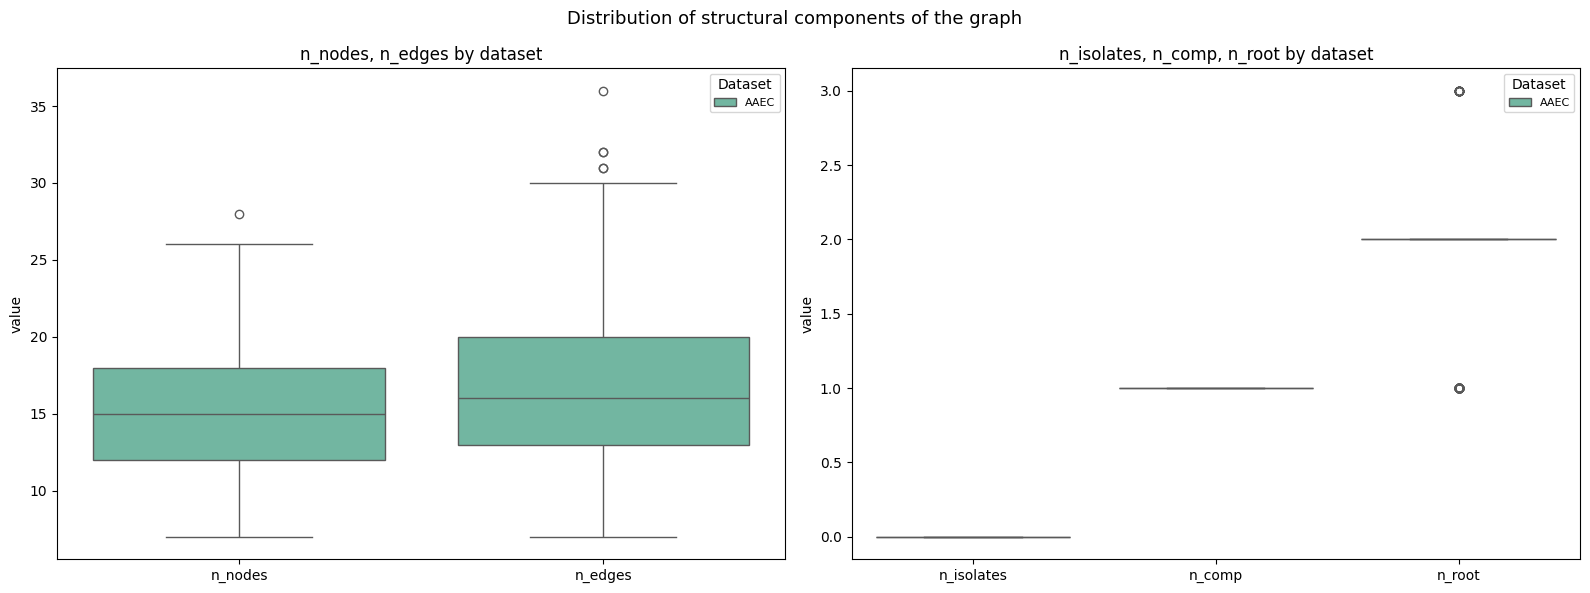

In [231]:
summary_comp_val_num(df)

### Caracteristicas de grafo

In [254]:
# Fazer alguma comparação
label_columna = "n_root"
df_comparacion = df[
    (df[label_columna] == 3) 
    # &
    # (df["dataset"] == "USD")
    # &
    # (df["n_edges"] == 0)
]
conteo = df_comparacion.groupby(label_columna).size()
lista = conteo.to_dict()
print(df_comparacion.shape)
print("Lista de componentes: ",lista)
df_comparacion

(18, 15)
Lista de componentes:  {3: 18}


,text_id,seg,info,graph,n_nodes,n_edges,n_isolates,n_comp,n_root,is_acyclic,is_connected,is_tree,is_arborescence,is_forest,dataset
738,AAEC_009,16,minimalist_labels labels_relation source...,"(AAEC_009_0, AAEC_009_1, AAEC_009_2, AAEC_009_...",16,17,0,1,3,True,True,False,False,False,AAEC
788,AAEC_059,19,minimalist_labels labels_relation source...,"(AAEC_059_0, AAEC_059_1, AAEC_059_2, AAEC_059_...",19,26,0,1,3,True,True,False,False,False,AAEC
808,AAEC_079,16,minimalist_labels labels_relation source...,"(AAEC_079_0, AAEC_079_1, AAEC_079_2, AAEC_079_...",16,19,0,1,3,True,True,False,False,False,AAEC
810,AAEC_081,20,minimalist_labels labels_relation source...,"(AAEC_081_0, AAEC_081_1, AAEC_081_2, AAEC_081_...",20,25,0,1,3,True,True,False,False,False,AAEC
830,AAEC_101,16,minimalist_labels labels_relation source...,"(AAEC_101_0, AAEC_101_1, AAEC_101_2, AAEC_101_...",16,19,0,1,3,True,True,False,False,False,AAEC
843,AAEC_114,14,minimalist_labels labels_relation source...,"(AAEC_114_0, AAEC_114_1, AAEC_114_2, AAEC_114_...",14,17,0,1,3,True,True,False,False,False,AAEC
851,AAEC_122,19,minimalist_labels labels_relation source...,"(AAEC_122_0, AAEC_122_1, AAEC_122_2, AAEC_122_...",19,26,0,1,3,True,True,False,False,False,AAEC
858,AAEC_129,16,minimalist_labels labels_relation source...,"(AAEC_129_0, AAEC_129_1, AAEC_129_2, AAEC_129_...",16,21,0,1,3,True,True,False,False,False,AAEC
859,AAEC_130,14,minimalist_labels labels_relation source...,"(AAEC_130_0, AAEC_130_1, AAEC_130_2, AAEC_130_...",14,15,0,1,3,True,True,False,False,False,AAEC
870,AAEC_141,20,minimalist_labels labels_relation source...,"(AAEC_141_0, AAEC_141_1, AAEC_141_2, AAEC_141_...",20,25,0,1,3,True,True,False,False,False,AAEC


In [255]:
# Recupera um registro
id_text_busca = "AAEC_009"
columna = "text_id"
result = df[df[columna] == id_text_busca]
if not result.empty: 
    result_info = result.iloc[0] 
else: 
    print("No existe: ", id_text_busca)

In [186]:
# result

In [121]:
# result_info["info"]

/tmp/ipykernel_23767/2138295617.py:3: DeprecationWarning: nx.nx_pydot.graphviz_layout depends on the pydot package, which has known issues and is not actively maintained. Consider using nx.nx_agraph.graphviz_layout instead.

See https://github.com/networkx/networkx/issues/5723
  pos = graphviz_layout(G, prog="dot")


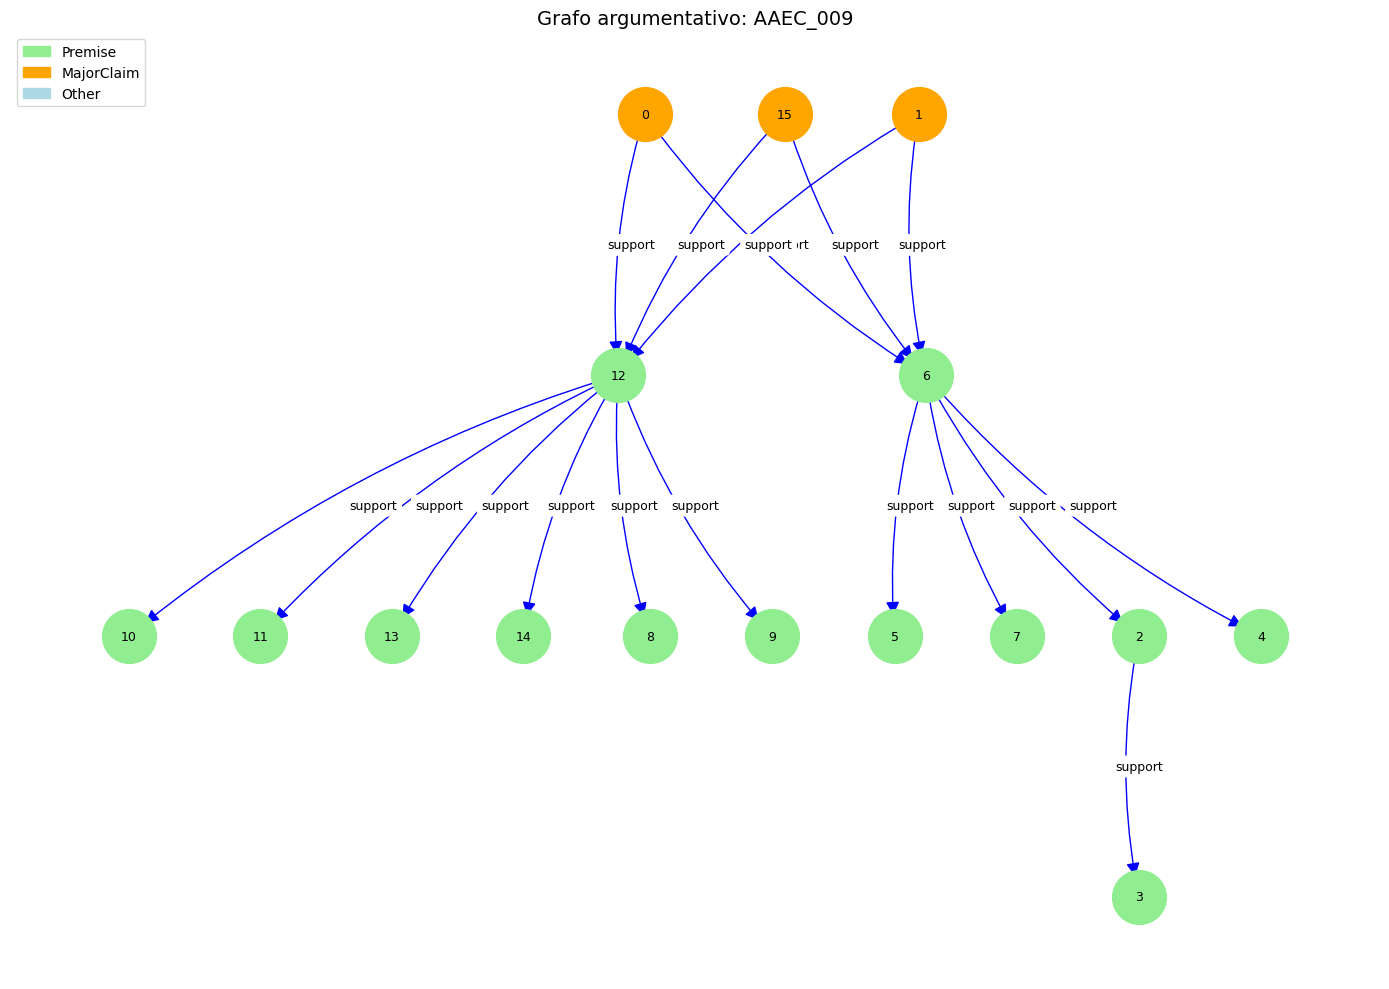

In [259]:
# Gráfica
di_graph(id_text_busca, result_info["graph"])
# di_graph(id_text_busca, result_info["graph"].reverse(copy=True)) # Invertir a direcção do grafo

## Estadisticas

In [192]:
# plot_estadisticas(df_comparacion)

### Verificar se os nós raiz são MajorClaim

In [235]:
# Diccionario de textos con nós raiz y tipo
data_raiz = {}
df_r = df_comparacion
# df_r = df_all
print(df_r.shape)
for idx, row in df_r.iterrows():
    data_raiz[row[columna]] = verificar_raices(row["graph"])
# data_raiz


(402, 15)


In [240]:
# Filtra los dataset que tem o no nós raiz MajorClaim
# problemas, label = filtrar_sin_major(data_raiz)
problemas, label = filtrar_con_major(data_raiz)

In [242]:
# Summary de nós raiz con/sin MajorClaim por Dataset 
resumen = resumen_por_dataset(problemas)

print(f"Total grafos {label} MajorClaim: {len(problemas)}")
print("================= Summary =================")
for dataset, cantidad in resumen.items():
    print(f"{dataset}: {cantidad} grafos")
print("================= Detail =================")
for text_id, raices in problemas.items():
    print(f"\n{text_id}")
    for nodo, info in raices.items():
        print(f"  {nodo} → {info['tipo']}")

Total grafos con MajorClaim: 402
================= Summary =================
AAEC: 402 grafos
================= Detail =================

AAEC_001
  AAEC_001_0 → MajorClaim
  AAEC_001_10 → MajorClaim

AAEC_002
  AAEC_002_0 → MajorClaim
  AAEC_002_13 → MajorClaim

AAEC_003
  AAEC_003_0 → MajorClaim
  AAEC_003_9 → MajorClaim

AAEC_004
  AAEC_004_1 → MajorClaim
  AAEC_004_10 → MajorClaim

AAEC_005
  AAEC_005_0 → MajorClaim
  AAEC_005_11 → MajorClaim

AAEC_006
  AAEC_006_0 → MajorClaim
  AAEC_006_18 → MajorClaim

AAEC_007
  AAEC_007_0 → MajorClaim

AAEC_008
  AAEC_008_0 → MajorClaim
  AAEC_008_11 → MajorClaim

AAEC_009
  AAEC_009_0 → MajorClaim
  AAEC_009_1 → MajorClaim
  AAEC_009_15 → MajorClaim

AAEC_010
  AAEC_010_0 → MajorClaim
  AAEC_010_15 → MajorClaim

AAEC_011
  AAEC_011_0 → MajorClaim
  AAEC_011_18 → MajorClaim

AAEC_012
  AAEC_012_12 → MajorClaim

AAEC_013
  AAEC_013_1 → MajorClaim
  AAEC_013_19 → MajorClaim

AAEC_014
  AAEC_014_12 → MajorClaim

AAEC_015
  AAEC_015_0 → MajorClaim

In [247]:
# Cantidad de nodos raiz con/sin Major Claim
print(f"========== Grafos {label} MajorClaim ==========")
resumen = defaultdict(int)
for instancia, componentes in problemas.items():  
    majorclaims = [comp for comp, datos in componentes.items() if datos['es_MajorClaim']]
    cantidad = len(majorclaims)
    if cantidad == 3:  # --------------> Revisar la cantidad por la que se esta filtrando
        dataset = extraer_dataset(instancia)
        # if dataset == 'AAEC':
            # print(f"{instancia}: {cantidad} MajorClaims → {majorclaims}")
        resumen[dataset] += 1
result = dict(resumen)
print(f"===========================================")
for dataset, cantidad in result.items():
    print(f"{dataset}: {cantidad} grafos")

========== Grafos con MajorClaim ==========
AAEC: 18 grafos
